**Assignment no. 4: Classification**

---


**Name:** Tejas Narayan Mahamuni

**PRN:** 202401040036

**Roll No.** 7

**Github Link:** https://github.com/tejas-mahamuni/machine-learning.git


### 1. Load Datasets and Mount Google Drive
This cell mounts your Google Drive to load both the unscaled and standardized F1 tyre datasets, followed by dropping the target-leaking feature `stint_length`.

In [3]:
# Load csv dataset from the drive

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

# unscaled data -> for profiling and from-scratch math (human-readable units)
df = pd.read_csv("/content/drive/MyDrive/AIML Lab/Mini Project/dataset/laps_2024.csv")

# scaled data -> for ridge/lasso/gradient descent later (they need it)
df_std = pd.read_csv("/content/drive/MyDrive/AIML Lab/Mini Project/dataset/laps_2024_std.csv")

# removing the leaky feature (it directly reveals the answer)
df = df.drop(columns=["stint_length"])
df_std = df_std.drop(columns=["stint_length"])
print(df.shape)

Mounted at /content/drive
(26206, 17)


In [4]:
df.head()

,circuit,driver_number,lap_duration,s1,s2,s3,tyre_age,RUL,pit_next_lap,tyre_HARD,tyre_INTERMEDIATE,tyre_MEDIUM,tyre_SOFT,tyre_WET,circuit_code,tyre_life_stage,rul_group
0,Yas Marina Circuit,1,99.877,25.002,39.931,34.944,0.0,28.0,0,0,0,1,0,0,22,fresh,pit_late
1,Yas Marina Circuit,1,114.938,18.209,54.569,42.160,1.0,27.0,0,0,0,1,0,0,22,fresh,pit_late
2,Yas Marina Circuit,1,98.051,23.196,41.997,32.858,2.0,26.0,0,0,0,1,0,0,22,fresh,pit_late
3,Yas Marina Circuit,1,89.504,18.166,38.187,33.151,3.0,25.0,0,0,0,1,0,0,22,fresh,pit_late
4,Yas Marina Circuit,1,89.813,18.056,37.945,33.812,4.0,24.0,0,0,0,1,0,0,22,fresh,pit_late


Select features and Target

In [33]:
# Features
features = [
    'lap_duration',
    's1',
    's2',
    's3',
    'tyre_age',
    # 'RUL',
    'circuit_code',
    'tyre_HARD',
    'tyre_INTERMEDIATE',
    'tyre_MEDIUM',
    'tyre_SOFT',
    'tyre_WET'
]

# Input and target
X = df_std[features].values
y = df_std['pit_next_lap'].values

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (26206, 11)
Y shape: (26206,)


Split dataset into training and testing

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 2. K-Nearest Neighbors (KNN)

#### 2.1 KNN Implementation From Scratch
This section contains a custom implementation of the K-Nearest Neighbors algorithm using basic Python and NumPy. It calculates Euclidean distances, sorts neighbors to find the majority vote, and evaluates model predictions without external machine learning packages.

In [7]:
class KNN:

    def __init__(self, k=5):
        self.k = k

    # Calculate Euclidean distance
    def euclidean_distance(self, x1, x2):

        distance = 0

        for i in range(len(x1)):
            distance += (x1[i] - x2[i]) ** 2

        return np.sqrt(distance)

    # Store training data
    def fit(self, X_train, y_train):

        self.X_train = X_train
        self.y_train = y_train

    # Predict a single data point
    def predict_single(self, x):

        distances = []

        # Calculate distance from every training point
        for i in range(len(self.X_train)):

            dist = self.euclidean_distance(x,self.X_train[i])

            distances.append((dist, self.y_train[i]))

        # Sort based on distance
        distances.sort(key=lambda x: x[0])

        # Select K nearest neighbours
        neighbors = distances[:self.k]

        # Extract class labels
        labels = [label for dist, label in neighbors]

        # Majority voting
        prediction = max(set(labels), key=labels.count)

        return prediction

    # Predict multiple test samples
    def predict(self, X_test):

        predictions = []

        for x in X_test:

            prediction = self.predict_single(x)

            predictions.append(prediction)

        return np.array(predictions)

    # Calculate accuracy
    def accuracy(self, y_true, y_pred):

        correct = 0

        for i in range(len(y_true)):

            if y_true[i] == y_pred[i]:
                correct += 1

        return correct / len(y_true)

##### Fitting Model
Initialize and train our custom KNN model on the training data.

In [8]:
knn = KNN(k=5)

# Train the model
knn.fit(X_train, y_train)

##### Predicting Values
Generate predictions on the test dataset.

In [9]:
y_pred = knn.predict(X_test)

print("Actual values:    ", y_test[:20])
print("Predicted values: ", y_pred[:20])

Actual values:     [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
Predicted values:  [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]


##### Accuracy Printing
Calculate and display the final classification accuracy of our custom KNN model.

In [10]:
accuracy = knn.accuracy(y_test, y_pred)

print("KNN Accuracy:", accuracy * 100, "%")

KNN Accuracy: 99.90461655856542 %


#### 2.2 KNN Implementation using Scikit-Learn Library
This section uses the official `KNeighborsClassifier` from the Scikit-Learn library to train on the data, evaluate performance, and display key metrics including a confusion matrix heatmap.

KNN Classification Results
--------------------------
Accuracy: 0.9734834032811904

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      5024
           1       0.81      0.48      0.60       218

    accuracy                           0.97      5242
   macro avg       0.89      0.74      0.79      5242
weighted avg       0.97      0.97      0.97      5242



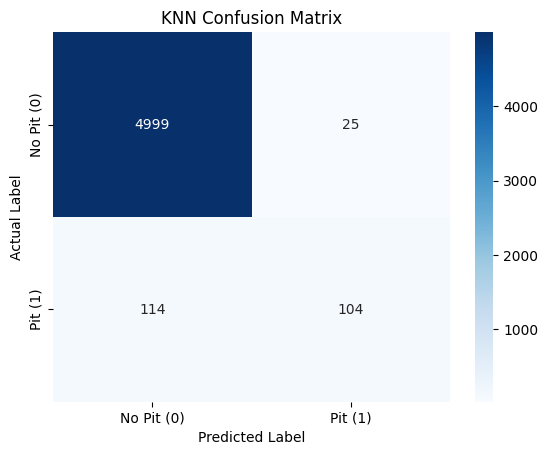

In [35]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

n_neighbors = 5

# Initialize KNN
knn_model = KNeighborsClassifier(n_neighbors=n_neighbors)
# Train the model
knn_model.fit(X_train, y_train)

# Predictions
y_pred_knn = knn_model.predict(X_test)

# Evaluation
print("KNN Classification Results")
print("--------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Pit (0)', 'Pit (1)'],
            yticklabels=['No Pit (0)', 'Pit (1)'])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("KNN Confusion Matrix")
plt.show()


### 3. Decision Tree Classifier

#### 3.1 Decision Tree Implementation From Scratch
This section implements a Decision Tree Classifier from scratch. It calculates Gini impurity, searches for optimal split thresholds across features, builds a binary tree recursively, and generates predictions based on the resulting tree.

Decision Tree

In [36]:
class DecisionTree:

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    # Calculate Gini impurity
    def gini(self, y):

        classes, counts = np.unique(y, return_counts=True)

        probabilities = counts / len(y)

        return 1 - np.sum(probabilities ** 2)

    # Find best feature and threshold
    def best_split(self, X, y):

        best_gain = 0
        best_feature = None
        best_threshold = None

        parent_gini = self.gini(y)
        n_samples, n_features = X.shape

        for feature in range(n_features):

            sorted_indices = np.argsort(X[:, feature])

            x_sorted = X[sorted_indices, feature]
            y_sorted = y[sorted_indices]

            classes = np.unique(y)
            class_map = {label: i for i, label in enumerate(classes)}

            encoded = np.array([class_map[label] for label in y_sorted])

            counts = np.zeros(len(classes))
            for i in encoded:
                counts[i] += 1

            left_counts = np.zeros(len(classes))

            for i in range(n_samples - 1):

                left_counts[encoded[i]] += 1

                # Skip identical feature values
                if x_sorted[i] == x_sorted[i + 1]:
                    continue

                right_counts = counts - left_counts

                n_left = i + 1
                n_right = n_samples - n_left

                gini_left = 1 - np.sum(
                    (left_counts / n_left) ** 2
                )

                gini_right = 1 - np.sum(
                    (right_counts / n_right) ** 2
                )

                weighted_gini = (
                    (n_left / n_samples) * gini_left +
                    (n_right / n_samples) * gini_right
                )

                gain = parent_gini - weighted_gini

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = (
                        x_sorted[i] + x_sorted[i + 1]
                    ) / 2

        return best_feature, best_threshold, best_gain

    # Build tree recursively
    def build_tree(self, X, y, depth=0):

        classes, counts = np.unique(y, return_counts=True)

        # Majority class
        majority_class = classes[np.argmax(counts)]

        # Stopping conditions
        if (
            len(classes) == 1 or
            depth >= self.max_depth or
            len(y) < self.min_samples_split
        ):
            return majority_class

        feature, threshold, gain = self.best_split(X, y)

        if feature is None or gain <= 0:
            return majority_class

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        if not np.any(left_mask) or not np.any(right_mask):
            return majority_class

        # Recursive splitting
        left_subtree = self.build_tree(
            X[left_mask], y[left_mask], depth + 1
        )

        right_subtree = self.build_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        return {
            'feature': feature,
            'threshold': threshold,
            'left': left_subtree,
            'right': right_subtree,
            'prediction': majority_class
        }

    # Train model
    def fit(self, X, y):

        self.tree = self.build_tree(X, y)

    # Predict one sample
    def predict_single(self, x, node=None):

        if node is None:
            node = self.tree

        if not isinstance(node, dict):
            return node

        if x[node['feature']] <= node['threshold']:
            return self.predict_single(x, node['left'])

        else:
            return self.predict_single(x, node['right'])

    # Predict multiple samples
    def predict(self, X):

        predictions = []

        for x in X:
            predictions.append(self.predict_single(x))

        return np.array(predictions)

    # Calculate accuracy
    def accuracy(self, y_true, y_pred):

        correct = np.sum(y_true == y_pred)

        return correct / len(y_true)


##### Fitting Model
Initialize and train our custom Decision Tree model.

In [37]:
# Create model
dt_model = DecisionTree(
    max_depth=5,
    min_samples_split=2
)

# Train
dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


##### Predicting Values
Generate predictions using our trained custom Decision Tree.

In [38]:
y_pred_dt = dt_model.predict(X_test)

print("Actual values:    ", y_test[:20])
print("Predicted values: ", y_pred_dt[:20])

Actual values:     [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
Predicted values:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### Accuracy Printing
Calculate and display the final prediction accuracy of our custom Decision Tree.

In [39]:
accuracy = dt_model.accuracy(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy * 100, "%")

Decision Tree Accuracy: 96.07020221289584 %


##### Evaluating Model
Generate and visualize the classification report and confusion matrix.

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      5024
           1       0.62      0.14      0.23       218

    accuracy                           0.96      5242
   macro avg       0.79      0.57      0.60      5242
weighted avg       0.95      0.96      0.95      5242



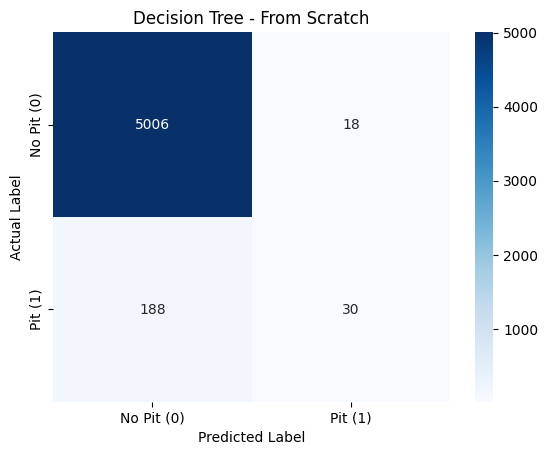

In [40]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_dt)

print("Classification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Pit (0)', 'Pit (1)'],
    yticklabels=['No Pit (0)', 'Pit (1)']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - From Scratch")
plt.show()

#### 3.2 Decision Tree Implementation using Scikit-Learn Library
Here, we use Scikit-Learn's optimized `DecisionTreeClassifier`. We visualize the decision rules using a plotting tree and compare its final accuracy with our custom 'from scratch' implementation.

Decision Tree Classification Results
------------------------------------
Accuracy: 0.9607020221289584

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      5024
           1       0.62      0.14      0.23       218

    accuracy                           0.96      5242
   macro avg       0.79      0.57      0.60      5242
weighted avg       0.95      0.96      0.95      5242



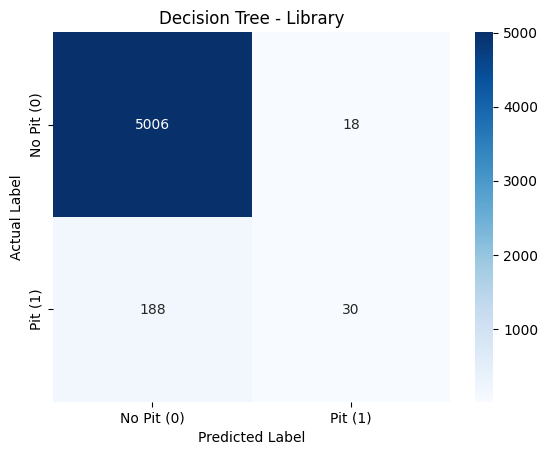

In [41]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize Decision Tree
dt_library = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=2,
    random_state=42
)

# Train model
dt_library.fit(X_train, y_train)

# Predictions
y_pred_dt_lib = dt_library.predict(X_test)

# Evaluation
print("Decision Tree Classification Results")
print("------------------------------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_dt_lib))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt_lib,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_dt_lib)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Pit (0)', 'Pit (1)'],
    yticklabels=['No Pit (0)', 'Pit (1)']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Library")
plt.show()


##### Visualizing the Decision Tree
Plot the decision rules and splits of the library-based Decision Tree classifier.

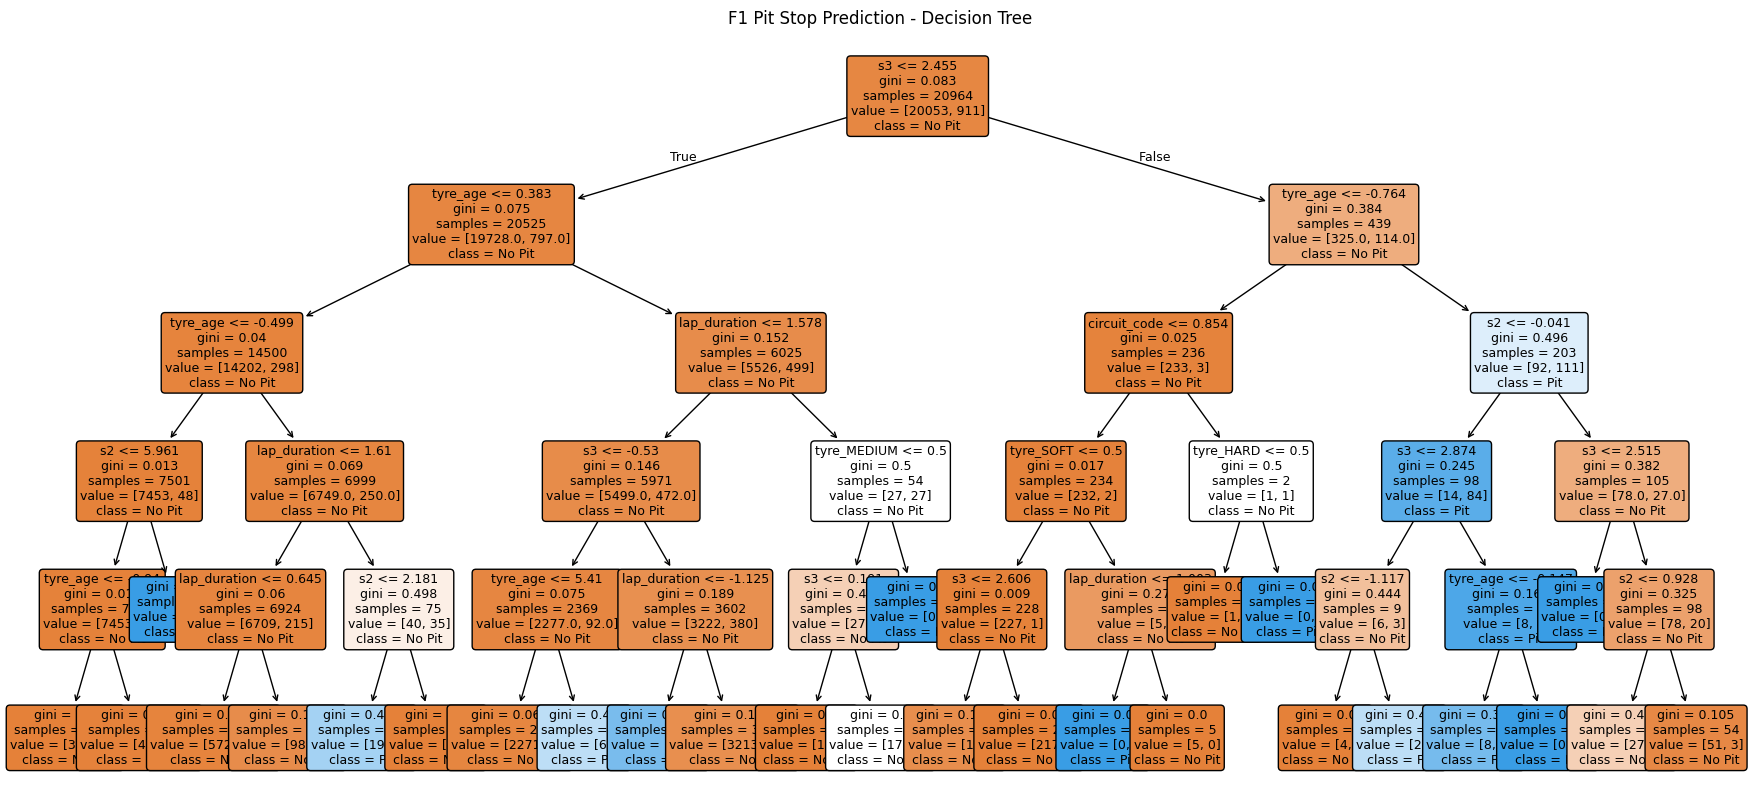

In [42]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    dt_library,
    feature_names=features,
    class_names=['No Pit', 'Pit'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("F1 Pit Stop Prediction - Decision Tree")
plt.show()

##### Comparing Performance
Compare the final accuracy of our custom implementation with the Scikit-Learn library model.

In [43]:
print("DECISION TREE COMPARISON")
print("------------------------")

print(
    "From Scratch Accuracy:",
    dt_model.accuracy(y_test, y_pred_dt) * 100
)

print(
    "Library Accuracy:",
    accuracy_score(y_test, y_pred_dt_lib) * 100
)

DECISION TREE COMPARISON
------------------------
From Scratch Accuracy: 96.07020221289584
Library Accuracy: 96.07020221289584



## 4. Naive Bayes Classification

Naive Bayes is a supervised machine learning classification algorithm based on Bayes' Theorem. It calculates the probability of a data point belonging to a particular class using prior probabilities and feature likelihoods.

In this project, Gaussian Naive Bayes is used to predict whether an F1 driver will make a pit stop on the next lap.

The target variable is `pit_next_lap`:
- 0: Driver does not pit on the next lap.
- 1: Driver pits on the next lap.

Gaussian Naive Bayes assumes that continuous input features follow a Gaussian (Normal) distribution within each class.

Bayes' Theorem:

P(C|X) = P(X|C) * P(C) / P(X)

Where:
- P(C|X): Posterior probability of the class.
- P(X|C): Likelihood of the features given the class.
- P(C): Prior probability of the class.
- P(X): Evidence.

Two implementations are developed:
1. Naive Bayes from scratch using Python and NumPy.
2. Naive Bayes using the Scikit-learn library.

Both implementations use the same dataset, input features, target variable and train-test split for fair comparison.



### 4.1.2 Implementing Naive Bayes Class

Gaussian Naive Bayes is implemented from scratch using a Python class.



##### Model Implementation
Define the Gaussian Naive Bayes class from scratch using NumPy.

In [44]:
class NaiveBayes:

    def __init__(self):
        self.classes = None
        self.mean = {}
        self.var = {}
        self.priors = {}

    # Training the model
    def fit(self, X_train, y_train):

        self.classes = np.unique(y_train)

        for c in self.classes:

            # Select samples belonging to class c
            X_c = X_train[y_train == c]

            # Calculate mean and variance
            self.mean[c] = np.mean(X_c, axis=0)
            self.var[c] = np.var(X_c, axis=0) + 1e-9

            # Calculate prior probability
            self.priors[c] = len(X_c) / len(X_train)

    # Gaussian probability density
    def gaussian_probability(self, x, mean, var):

        exponent = np.exp(-((x - mean) ** 2) / (2 * var))

        denominator = np.sqrt(2 * np.pi * var)

        return exponent / denominator

    # Predict a single sample
    def predict_single(self, x):

        posterior_probs = []

        for c in self.classes:

            # Log prior probability
            log_prob = np.log(self.priors[c])

            # Calculate log likelihood
            probabilities = self.gaussian_probability(
                x,
                self.mean[c],
                self.var[c]
            )

            log_prob += np.sum(np.log(probabilities + 1e-300))

            posterior_probs.append(log_prob)

        # Return class with maximum posterior probability
        return self.classes[np.argmax(posterior_probs)]

    # Predict multiple samples
    def predict(self, X_test):

        predictions = []

        for x in X_test:

            predictions.append(self.predict_single(x))

        return np.array(predictions)

    # Calculate accuracy
    def accuracy(self, y_true, y_pred):

        correct = np.sum(y_true == y_pred)

        return correct / len(y_true)

##### Fitting Model
Initialize and fit the custom Gaussian Naive Bayes model on training data.

In [45]:
# Initialize Naive Bayes model
nb_model = NaiveBayes()

# Train the model
nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


##### Predicting Values
Generate predictions on the test dataset using our from-scratch model.

In [46]:
# Predict test samples
y_pred_nb = nb_model.predict(X_test)

print("Actual values:    ", y_test[:20])
print("Predicted values: ", y_pred_nb[:20])

Actual values:     [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
Predicted values:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


##### Accuracy Printing
Calculate and print the classification accuracy and error rate of the custom model.

In [47]:
# Calculate accuracy
accuracy = nb_model.accuracy(y_test, y_pred_nb)

# Calculate error
error = 1 - accuracy

print("Naive Bayes - From Scratch")
print("--------------------------")

print("Accuracy:", accuracy * 100, "%")
print("Error:", error * 100, "%")

Naive Bayes - From Scratch
--------------------------
Accuracy: 94.46776039679511 %
Error: 5.53223960320488 %



### 4.1.6 Confusion Matrix and Classification Report

A confusion matrix is used to analyze the classification performance of the model.

It consists of four components:
- True Positive (TP): Correctly predicted pit stops.
- True Negative (TN): Correctly predicted non-pit stops.
- False Positive (FP): Predicted pit stop when no pit stop occurred.
- False Negative (FN): Actual pit stop incorrectly predicted as no pit stop.

Precision, recall and F1-score are also calculated to provide a detailed evaluation, particularly for the pit-stop class.


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      5024
           1       0.18      0.10      0.13       218

    accuracy                           0.94      5242
   macro avg       0.57      0.54      0.55      5242
weighted avg       0.93      0.94      0.94      5242



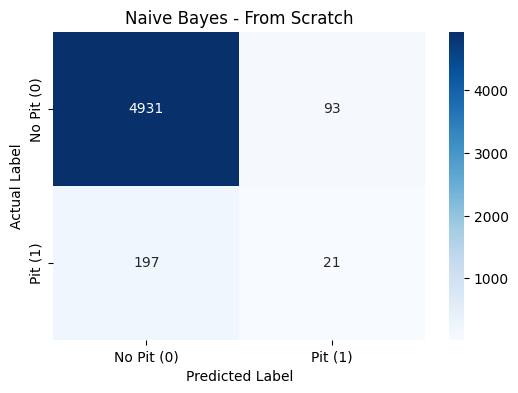

In [48]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

import seaborn as sns
import matplotlib.pyplot as plt

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_nb)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    zero_division=0
))

plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Pit (0)', 'Pit (1)'], yticklabels=['No Pit (0)', 'Pit (1)'])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naive Bayes - From Scratch")
plt.show()


### 4.2.1 Model Implementation and Training

The Gaussian Naive Bayes algorithm is implemented using the Scikit-learn machine learning library.

The GaussianNB class automatically calculates prior probabilities, feature means and variances during training.

The model is trained using the same training dataset used in the from-scratch implementation to ensure a fair comparison.



##### Fitting Model
Initialize and train Scikit-learn's GaussianNB model.

In [49]:

from sklearn.naive_bayes import GaussianNB

# Initialize Gaussian Naive Bayes
nb_library = GaussianNB()

# Train the model
nb_library.fit(X_train, y_train)

print("Gaussian Naive Bayes trained successfully!")


Gaussian Naive Bayes trained successfully!


##### Predicting Values
Generate predictions on the test dataset using the library model.

In [59]:
# Predictions
y_pred_nb_lib = nb_library.predict(X_test)

print("Actual values:    ", y_test[4900:])
print("Predicted values: ", y_pred_nb_lib[4900:])

Actual values:     [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1
 0 0 0 0 1 0 0 1 0]
Predicted values:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0

In [51]:
from sklearn.metrics import accuracy_score

accuracy_nb_lib = accuracy_score(y_test, y_pred_nb_lib)

error_nb_lib = 1 - accuracy_nb_lib

print("Naive Bayes - Library")
print("---------------------")

print("Accuracy:", accuracy_nb_lib * 100, "%")
print("Error:", error_nb_lib * 100, "%")

Naive Bayes - Library
---------------------
Accuracy: 94.46776039679511 %
Error: 5.53223960320488 %


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      5024
           1       0.18      0.10      0.13       218

    accuracy                           0.94      5242
   macro avg       0.57      0.54      0.55      5242
weighted avg       0.93      0.94      0.94      5242



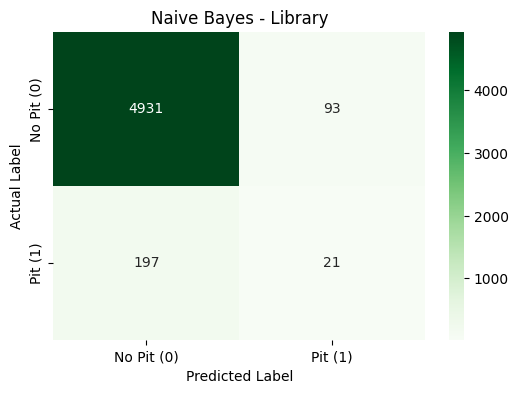

In [52]:
cm = confusion_matrix(y_test, y_pred_nb_lib)

print("Classification Report:")
print(classification_report(y_test, y_pred_nb_lib, zero_division=0))

plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=['No Pit (0)', 'Pit (1)'], yticklabels=['No Pit (0)', 'Pit (1)'])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naive Bayes - Library")
plt.show()

In [53]:
comparison_nb = pd.DataFrame({
    'Implementation': [
        'Naive Bayes From Scratch',
        'Naive Bayes Library'
    ],

    'Accuracy': [
        nb_model.accuracy(y_test, y_pred_nb) * 100,
        accuracy_score(y_test, y_pred_nb_lib) * 100
    ],

    'Error': [
        (1 - nb_model.accuracy(y_test, y_pred_nb)) * 100,
        (1 - accuracy_score(y_test, y_pred_nb_lib)) * 100
    ]
})

print(comparison_nb)

             Implementation  Accuracy    Error
0  Naive Bayes From Scratch  94.46776  5.53224
1       Naive Bayes Library  94.46776  5.53224


In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

models = {
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt_lib,
    'Naive Bayes': y_pred_nb_lib
}

for name, predictions in models.items():

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df)

       Algorithm  Accuracy  Precision    Recall  F1 Score
0            KNN  0.973483   0.806202  0.477064  0.599424
1  Decision Tree  0.960702   0.625000  0.137615  0.225564
2    Naive Bayes  0.944678   0.184211  0.096330  0.126506
